# Week 11 — Forecast Explainability and Bias Audit

**===== WEEK 11 START =====**

Objective: explain next-month airline passenger forecasts, measure differences in error by route history and airport coverage, and evaluate a training-data treatment against the Week 10 benchmark.

## 1. Project environment and Week 10 benchmark

Run from the project repository using the Week 11 environment. Load the saved 16-input MLP_B_temporal model and the audit functions used throughout the notebook.

In [1]:
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'Src/week11_audit.py').exists())
sys.path.insert(0, str(root/'Src'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import week11_audit as audit
from threadpoolctl import threadpool_limits
limits = threadpool_limits(limits=2)
bundle = audit.joblib.load(audit.BUNDLE)
def table(name):
    return pd.read_csv(audit.OUT / (name+'.csv'))
print('Selected model: MLP_B_temporal | Inputs:', len(bundle['feature_order']))

Selected model: MLP_B_temporal | Inputs: 16


## 2. Reconstruct the chronological partitions

The Week 2 aggregator reads all annual archives. Week 5 reconstructs the reference-month operational fields. Week 10 joins exact calendar history before filtering rows with known next-month labels. The saved bundle supplies training medians, scaling and PCA loadings.

In [2]:
frames = audit.build_partitions(bundle)
display(pd.DataFrame([{'Split': s, 'Rows': len(f), 'From': str(f.TargetPeriod.min())[:7],
                       'Through': str(f.TargetPeriod.max())[:7]}
                      for s,f in frames.items()]))

,Split,Rows,From,Through
0,Training,1062603,2015-02,2022-12
1,Validation,239395,2023-01,2024-08
2,Test,264291,2024-09,2026-05


## 3. Rank predictors by validation error

Shuffle each input on a reproducible sample of 8,192 rows and measure the increase in passenger MAE. Twelve repeats quantify variation across shuffles. Joint shuffles retain dependencies inside each feature block.

In [3]:
audit.importance(bundle, frames)
imp = table('importance')
display(imp.query("Type=='Feature'").head(10).round(2))
display(imp.query("Type=='Block'").round(2))

,Type,Predictor,Increase,RepeatSD,SampleMAE
1,Feature,PassengerLag1Log1p,2238.98,33.82,813.39
2,Feature,PassengerRolling3MeanLog1p,866.21,19.27,813.39
4,Feature,PassengerLag11Log1p,683.95,7.69,813.39
6,Feature,AnnualLogChangeMissing,581.31,26.85,813.39
7,Feature,PassengerLag12Log1p,573.36,12.58,813.39
8,Feature,PC1,559.77,17.75,813.39
10,Feature,MonthlyLogChange,514.82,9.66,813.39
11,Feature,PassengerRolling3MeanMissing,501.70,17.02,813.39
12,Feature,AnnualLogChange,458.72,12.91,813.39
13,Feature,PassengerLag1Missing,390.93,19.24,813.39


,Type,Predictor,Increase,RepeatSD,SampleMAE
0,Block,Recent history,3159.47,30.61,813.39
3,Block,Prior target season,693.48,8.67,813.39
5,Block,Annual history,671.19,14.54,813.39
9,Block,PC1,559.77,17.75,813.39
20,Block,PC2,21.77,2.03,813.39


## 4. Plot the leading predictors

The bars show increases in validation MAE when each input is shuffled. Error bars show one standard deviation across the 12 shuffles.

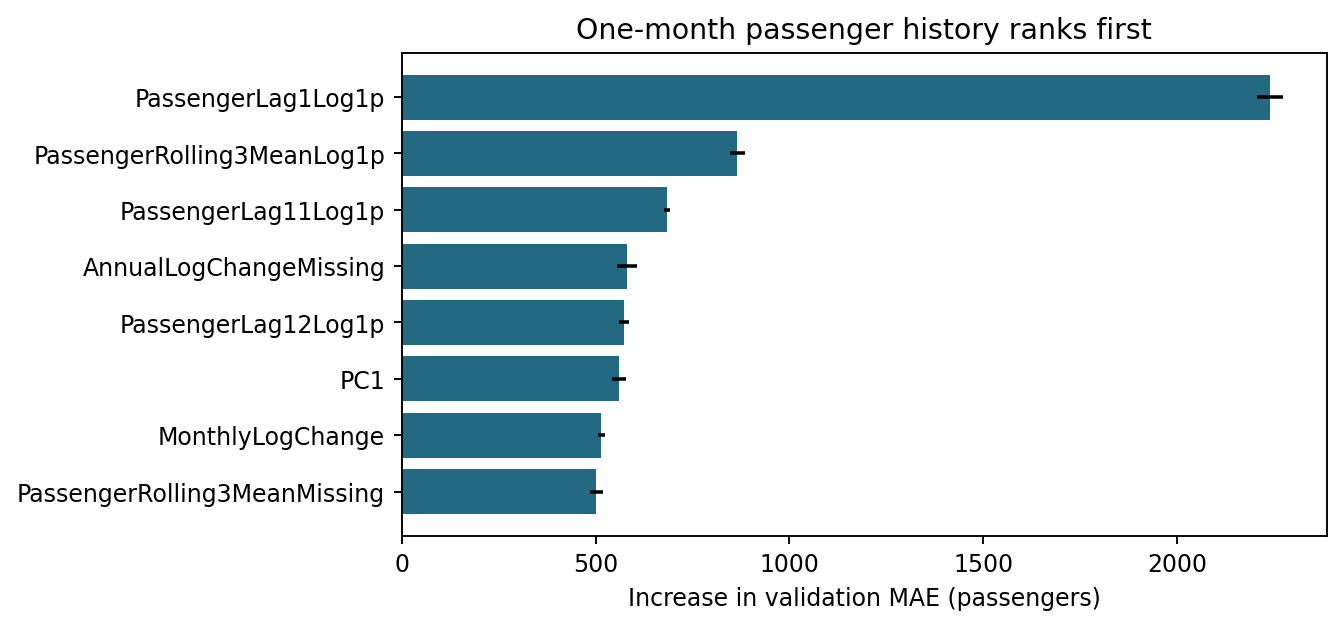

In [4]:
top = imp.query("Type=='Feature'").head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8,3.8))
ax.barh(top.Predictor, top.Increase, xerr=top.RepeatSD, color='#226981')
ax.set_xlabel('Increase in validation MAE (passengers)')
ax.set_title('One-month passenger history ranks first')
fig.tight_layout()
figdir = root / 'Reports/week11/figures'
figdir.mkdir(exist_ok=True, parents=True)
fig.savefig(figdir/'global_importance.png',dpi=170,bbox_inches='tight')
from IPython.display import Image
display(Image(filename=str(figdir/'global_importance.png')))
plt.close(fig)

## 5. Explain five individual forecasts

Sample five test rows without replacement (seed 113). Enumerate all 32 coalitions of five feature blocks over 64 training reference rows. The contributions sum to the forecast minus the mean reference forecast. For each row, vary prior-year target-month passengers over a training-derived grid. A material change is at least 50 passengers and 10% of the starting forecast. The scenario table reports the closest qualifying count on the grid and the resulting change in forecast.

In [5]:
audit.local_cases(bundle, frames)
cases = table('cases').set_index('Case')
display(cases[['Carrier','Route','Month','Actual','Forecast']].round(1))
display(table('attributions').set_index('Case').round(1))
display(cases[['Threshold','PriorCount','ScenarioCount','ScenarioForecast','Change']].round(1))

,Carrier,Route,Month,Actual,Forecast
Case,,,,,
1,WN,DEN–RSW,2025-04,4613.0,3259.5
2,G4,PIE–XNA,2025-05,1287.0,1241.6
3,MQ,ICT–PHX,2025-12,1960.0,2833.3
4,DL,IAD–DCA,2026-03,2.0,680.7
5,C5,AMA–IAH,2026-05,3436.0,3253.4


,Reference,PC1,PC2,Recent history,Prior target season,Annual history
Case,,,,,,
1,4837.4,41.4,-288.5,98.4,-930.5,-498.6
2,4837.4,-70.3,5.9,-2222.5,-462.7,-846.2
3,4837.4,-110.8,-35.0,-1548.2,-290.9,-19.2
4,4837.4,-790.6,26.2,-955.3,-474.4,-1962.7
5,4837.4,-258.9,-79.4,-1060.0,-32.7,-153.0


,Threshold,PriorCount,ScenarioCount,ScenarioForecast,Change
Case,,,,,
1,326.0,2032.0,2369,3587.1,327.6
2,124.2,1359.0,1542,1366.6,125.0
3,283.3,NaN,1907,3118.7,285.5
4,68.1,380.0,207,608.2,-72.4
5,325.3,2654.0,592,2923.8,-329.6


## 6. Compare errors by airport coverage

An origin’s exposure is its number of training carrier-route-month records. Set the cutoff at the row-weighted training 25th percentile. Unseen origins have exposure zero. Use the test data only to describe the resulting groups.

In [6]:
audit.airports(bundle,frames)
display(table('origin_exposure').T.round(2))

,0,1
Group,Lower exposure,Higher exposure
UpperCutoffForLowerGroup,2388,2388
Rows,67161,197130
Origins,617,89
MissingHistoryPct,18.978276,13.533201
MAE,450.899144,905.912224
RMSE,790.936903,1412.161198
R2,0.939994,0.972866
MeanResidual,-140.203,-190.508613
WAPE_Percent,21.864243,13.657962


## 7. Retrain the model and compare subgroup errors

Resample the training rows with missing prior-season history, adding half their original count with replacement, using seed 111. Clone and retrain the winning neural network. Score both estimators on the original unchanged splits. All five metrics for the saved model must reconcile with the archived Week 10 records. Positive mean residual indicates underforecasting. WAPE divides summed absolute error by summed observed passengers.

In [7]:
audit.evaluate(bundle,frames)
display(table('training_treatment'))
metrics = table('metrics')
display(metrics.round(3))

,Original,OriginalMissing,Added,Treated,Epochs
0,1062603,303332,151666,1214269,23


,Split,Model,Rows,MAE,RMSE,R2,MeanResidual,WAPE_Percent
0,Training,Week 10,1062603,808.166,1434.789,0.966,-140.448,16.008
1,Training,Reweighted,1062603,803.660,1432.557,0.966,-58.815,15.918
2,Validation,Week 10,239395,809.332,1299.810,0.974,-95.610,14.006
3,Validation,Reweighted,239395,813.944,1323.037,0.973,37.898,14.086
4,Test,Week 10,264291,790.285,1283.125,0.973,-177.725,14.444
5,Test,Reweighted,264291,779.510,1281.807,0.973,-46.096,14.247


In [8]:
groups = table('subgroups')
display(groups.query("Model=='Week 10'")[['Split','History','Rows','Share','MeanActual',
        'MeanForecast','UnderRate']].round(3))
display(groups[['Split','Model','History','MAE','WAPE_Percent','MeanResidual']].round(2))

,Split,History,Rows,Share,MeanActual,MeanForecast,UnderRate
0,Training,observed,759271,0.715,5748.437,5917.758,0.370
1,Training,missing,303332,0.285,3296.942,3365.116,0.393
4,Validation,observed,202345,0.845,6529.898,6618.692,0.403
5,Validation,missing,37050,0.155,1675.379,1808.215,0.363
8,Test,observed,224867,0.851,6167.577,6347.601,0.370
9,Test,missing,39424,0.149,1500.435,1665.048,0.329


,Split,Model,History,MAE,WAPE_Percent,MeanResidual
0,Training,Week 10,observed,853.30,14.84,-169.32
1,Training,Week 10,missing,695.20,21.09,-68.17
2,Training,Reweighted,observed,847.60,14.74,-28.30
3,Training,Reweighted,missing,693.68,21.04,-135.19
4,Validation,Week 10,observed,849.02,13.00,-88.79
5,Validation,Week 10,missing,592.56,35.37,-132.84
6,Validation,Reweighted,observed,855.74,13.10,73.28
7,Validation,Reweighted,missing,585.69,34.96,-155.36
8,Test,Week 10,observed,831.36,13.48,-180.02
9,Test,Week 10,missing,556.03,37.06,-164.61


## 8. Reproducibility and completion checks

Reweighting raised validation MAE from 809.33 to 813.94 passengers. Retain the Week 10 benchmark. The previously examined test period describes historical performance. The history and airport groups do not identify passenger demographics.

In [9]:
assert len(cases)==5 and len(metrics)==6 and len(groups)==12
print('Audit complete. Full-partition baseline reconciled on every split.')

Audit complete. Full-partition baseline reconciled on every split.


**===== WEEK 11 END =====**